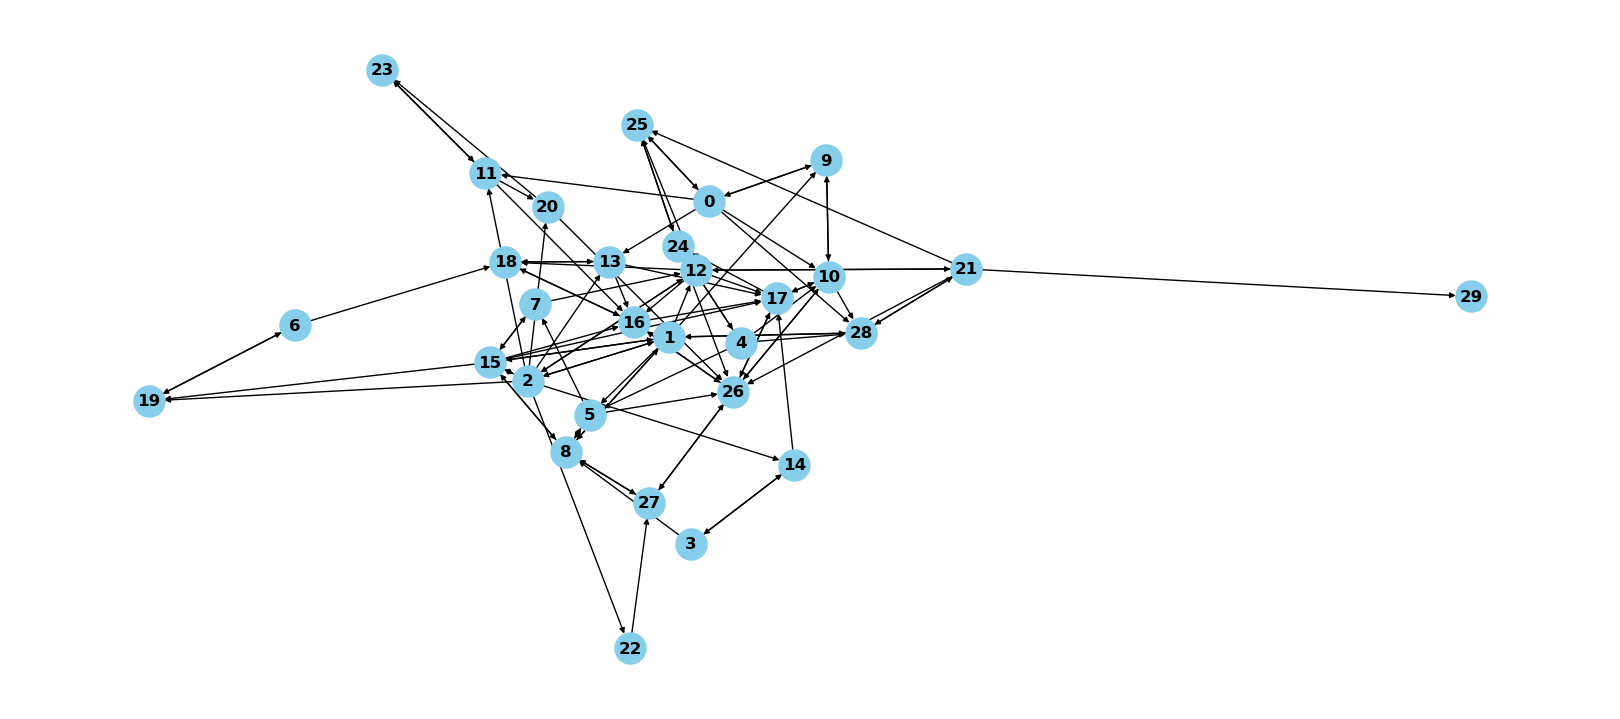

In [43]:
import matplotlib.pyplot as plt
import networkx as nx 
import numpy as np

constructor = [(20,60, 0.7), (10, 40, 0.25)]
np.random.seed(123)
G = nx.random_shell_graph(constructor, seed=123).to_directed()
G.remove_edges_from([(u, v) for u, v in G.edges() if u>v and np.random.random() < 0.6])
plt.figure(figsize=(16, 7))
kwargs = dict(pos=nx.spring_layout(G, seed=123), arrowsize=8, node_color='skyblue', with_labels=True, font_weight='bold', node_size=500)
nx.draw(G, **kwargs)
plt.show()

In [ ]:
def random_config(seed:int=123, shell_constructor:list=[(20,60, 0.7), (10, 40, 0.25)], cases:int=3):
    G = nx.random_shell_graph(shell_constructor, seed=123).to_directed()
    np.random.seed(seed)
    val = np.random.random()
    G.remove_edges_from([(u, v) for u, v in G.edges() if u>v and np.random.random() < val])
    nodes_without_zero = [n for n in G.nodes() if n != 0]
    node_subsets = []
    for _ in range(cases):
        num_dec = 0
        while num_dec < 6:
            nodes = np.append(np.array(np.random.choice(nodes_without_zero, size=10, replace=False)), 0)
            subgraph = G.subgraph(nodes)
            num_dec = len(nx.descendants(subgraph, 0))
        node_subsets.append(nodes)
    return G, [G.subgraph(nodes) for nodes in node_subsets]


SIM_CONFIG = {
    'node_params1': np.random.beta,
    'node_params2': np.random.normal, 
    'edge_params1': np.random.beta,
    'edge_params2': np.random.weibull,
    'edge_params3': np.random.beta,
}

RANDOM_PARAM_STATES = {
    'node_params1': np.linspace(0.1, 0.9, 4),
    'edge_params1': np.linspace(0.7, 0.9, 3),
    'edge_params2': np.linspace(16, 20, 3),
}

class Sim:
    def __init__(self, G, n_sim:int=1000, cases:list=None, param_states:dict=None, seed:int=123):
        self.G = G
        self.n_sim = n_sim
        self.seed = seed
        self.cases = cases
        self.param_states = param_states
        self._assign_params()
        
    def _assign_params(self):
        np.random.seed(self.seed)
        self.node_params1 = {n: (np.random.randint(20, 30), np.random.randint(1, 10)) for n in self.G.nodes()}
        self.node_params2 = {n: (np.random.uniform(10, 20), np.random.uniform(1, 3)) for n in self.G.nodes()}

        self.edge_params1 = {(u, v): (np.random.randint(20,30), np.random.randint(1, 10)) for u, v in self.G.edges()}
        self.edge_params2 = {(u, v): (np.random.uniform(10, 20), np.random.uniform(0, 2), np.random.uniform(0.5, 3)) for u, v in self.G.edges()}
        self.edge_params3 = {
            (u, v): (
                (np.random.randint(1, 10), np.random.randint(1, 10)), 
                (np.random.randint(1, 10), np.random.randint(1, 10))
                ) for u, v in self.G.edges()
                }
        self.edge_params4 = {(u, v): (np.random.uniform(0, 1), np.random.uniform(0, 1)) for u, v in self.G.edges()}

    def _configure_simulation_matrix(self):
        feature_space = len(self.G.nodes()) + 2*len(self.G.edges())



sim = Sim(G, n_sim=1000)


In [ ]:
subgraphs = random_config()


array([0.        , 0.26666667, 0.53333333, 0.8       ])

In [35]:
M1 = np.random.random(size=(3,3,100))
M1.shape

(3, 3, 100)

In [ ]:
import networkx as nx

class Endpoint_Calculator:
    """ 
    There are functionalities that nx does not have. Customized traversal methods are required for this motivation:

        Suppose there exists a graph G with the following branches: 
            0 --> 1 --> 2 <--> 3
            0 --> 100 --> 2 --> 4 
        Typically, endpoints are calcuated by considering all nodes with out-degree 0 
            OR nodes with the only out degree such that out-nodes are artifical. 
        Finding node 4 in endpoint calcuations is trival by looking at breadth-first-search predecessors.
        Neither out-degree, nor bfs-predecssors can identify 3 as an endpoint. Therefore, this class is a requirement.  
    """
    def __init__(self, g: nx.DiGraph):
            self.graph = g
            self.adj = dict(g.adjacency())

    def new_graph(self, g: nx.DiGraph):
        self.graph = g
        self.adj = dict(g.adjacency())

    def find_branch_endpoints(self, start_node):
        # BFS shortest paths and depths
        paths = nx.single_source_shortest_path(self.graph, start_node)
        depth = {node: len(path) - 1 for node, path in paths.items()}
        reachable = set(paths)
        endpoints = set()
        # Restrict the graph to nodes reachable from the start
        graph = self.graph.subgraph(reachable)
        endpoints = set()
        for node in reachable:
            successors = list(graph.successors(node))
            # Condition 1: True sink
            if not successors:
                endpoints.add(node)
                continue
            # Condition 2: Single outgoing edge returning to a shallower BFS layer
            if (len(successors) == 1 and depth[successors[0]] < depth[node]):
                endpoints.add(node)
                continue
            # Condition 3: No distinct reachable node at the same or a deeper layer
            descendants = nx.descendants(graph, node)
            has_forward_continuation = any(depth[other] >= depth[node] for other in descendants if other != node)
            if not has_forward_continuation:
                endpoints.add(node)
        return list(endpoints)


Endpoints: [25, 18]


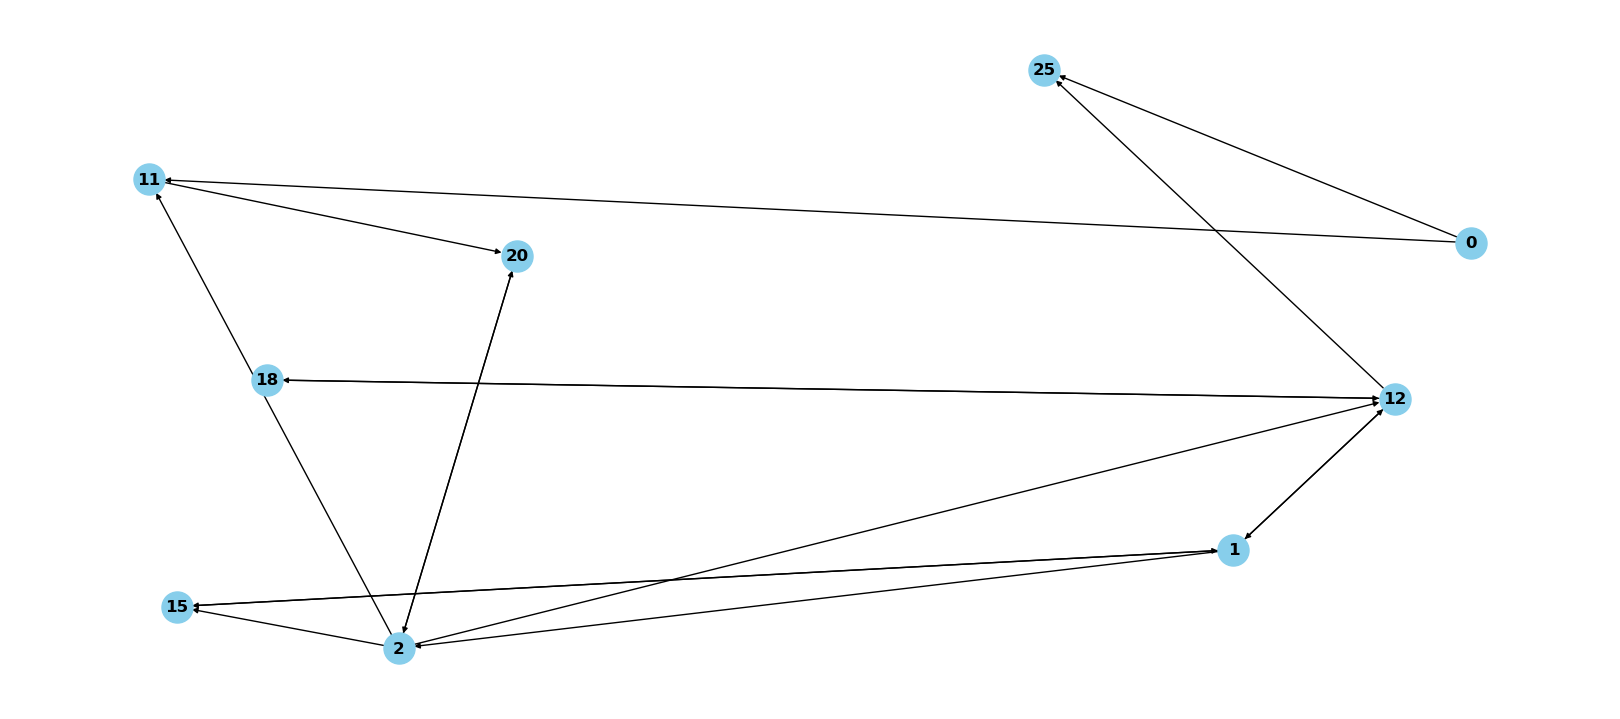

Endpoints: [25, 26, 28]


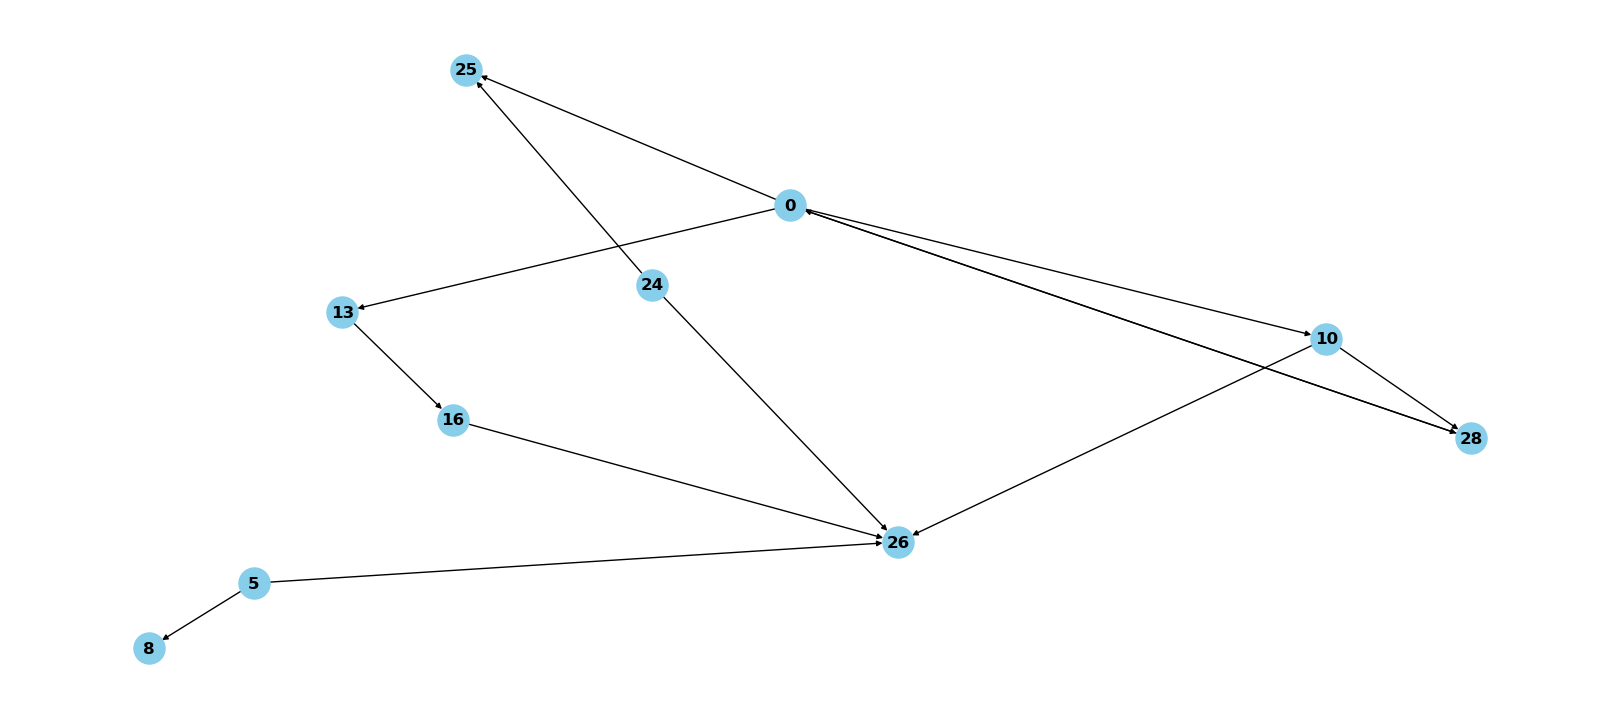

Endpoints: [19, 25, 3]


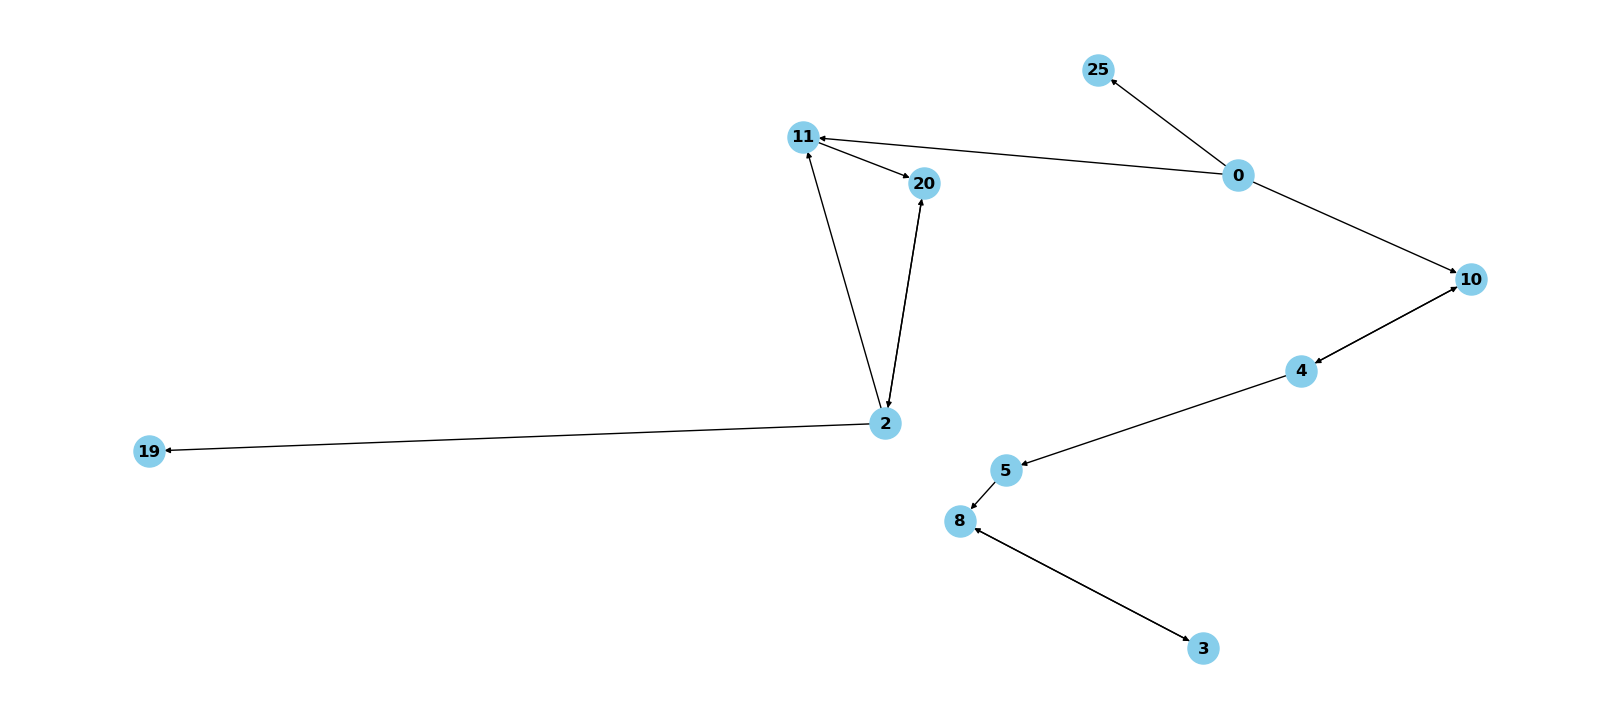

In [44]:

ec = Endpoint_Calculator(G)

subgraphs = random_config()
kwargs = dict(pos=nx.spring_layout(G, seed=123), arrowsize=8, node_color='skyblue', with_labels=True, font_weight='bold', node_size=500)


for g in subgraphs:
    g = g.copy()
    g.remove_nodes_from(list(nx.isolates(g)))
    ec.new_graph(g)
    endpoints = ec.find_branch_endpoints(0)
    print(f'Endpoints: {endpoints}')


    plt.figure(figsize=(16, 7))
    nx.draw(g, **kwargs)
    plt.show()

In [42]:
n_sim = 100
feature_space = len(G.nodes()) + 2*len(G.edges())
cases = 3
param_states = 3
M = np.zeros(
    (feature_space, cases, param_states, n_sim), dtype=bool
    )
M.shape

(224, 3, 3, 100)